# Ejercicio 6: Parquet versus tablas persistentes de DuckDB

Objetivo: comparar siete consultas analíticas con tres volúmenes reales de 2024 y 2026, incluyendo el tiempo y espacio de materialización. La estrategia más rápida se determina con las mediciones, para cada consulta y conjunto.

Este notebook presenta los CSV producidos por `scripts/medir_rendimiento.py`. **No ejecuta el benchmark ni abre las bases de viajes.** El informe completo y los comandos PowerShell están en `docs/resultados/ejercicio_6_benchmark.md`.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

raiz = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "scripts/laboratorio").is_dir())
sys.path.insert(0, str(raiz / "scripts"))
from laboratorio.parametros import Configuracion
config = Configuracion.del_entorno()
carpeta = config.resultados
experimento = json.loads((carpeta / "benchmark.json").read_text(encoding="utf-8"))
assert experimento["estado"] == "completo", "El benchmark está incompleto o falló; no publicar como exitoso"
tablas = pd.read_csv(carpeta / "benchmark_tablas.csv")
tiempos = pd.read_csv(carpeta / "benchmark_tiempos.csv")
individuales = pd.read_csv(carpeta / "benchmark_individuales.csv")
equivalencia = pd.read_csv(carpeta / "benchmark_equivalencia.csv")
assert individuales.estado.eq("ok").all()
assert tiempos.mismo_resultado.all() and equivalencia.mismo_resultado.all()
orden = tablas.conjunto.tolist()
etiquetas = dict(zip(["1 mes", "8 meses", "20 meses"], ["A: enero 2026", "B: enero-agosto 2026", "C: 2024 + enero-agosto 2026"]))
colores = {"parquet": "#2879bd", "tabla": "#df6b36"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

## Estrategias y metodología

Parquet directo usa `read_parquet(..., union_by_name=true, filename=true)` y las vistas normalizadas existentes. La tabla persistente almacena **todas las filas de la vista `viajes`**, con las mismas columnas y tipos, y copia el catálogo de zonas. No prefiltra ni preagrega los viajes. El periodo y las columnas comunes ya quedan calculados en la tabla; su costo está incluido en la materialización. `viajes_validos`, las macros y el SQL analítico son compartidos.

Se materializa mes a mes dentro de una transacción. El tiempo incluye inserciones, catálogo, vistas, commit, checkpoint y detach. Las bases se crean en una carpeta nueva por ejecución, separadas de Metabase. Antes de cada conjunto se comprueban RAM y disco; no se cargan los viajes en pandas.

Por consulta y estrategia se abre una conexión nueva, se ejecuta un calentamiento y luego cinco mediciones en esta ejecución real. Se mide `execute().fetchall()` con reloj monotónico; conexión, EXPLAIN, comparaciones y escritura de CSV quedan fuera del intervalo. Las estrategias corren secuencialmente y su orden inicial alterna por consulta/conjunto. Se cierran todas las conexiones. El resumen excluye el calentamiento y muestra mediana, mínimo y máximo.

La caché del sistema operativo **no está controlada**. Materializar y medir una estrategia puede beneficiar a la siguiente. El calentamiento prepara cada conexión, pero no garantiza igualdad de cachés ni una caché fría real. Los resultados son tiempos de este entorno, no pruebas universales ni intervalos de confianza.

In [2]:
display(pd.DataFrame([{
    "DuckDB": experimento["duckdb"], "Python": experimento["python"],
    "sistema": experimento["sistema"], "hilos": experimento["configuracion"]["threads"],
    "memory_limit": experimento["configuracion"]["memory_limit"],
    "temporales_max": experimento["configuracion"]["max_temp_directory_size"],
    "repeticiones": experimento["repeticiones"], "ejecucion": experimento["ejecucion"]
}]))
display(pd.DataFrame(experimento["recursos"])[["conjunto", "disponible_efectiva_bytes", "disco_libre_bytes", "espacio_estimado_bytes"]])

,DuckDB,Python,sistema,hilos,memory_limit,temporales_max,repeticiones,ejecucion
0,1.5.5,3.11.14,Linux-5.15.167.4-microsoft-standard-WSL2-x86_6...,2,1GiB,4GiB,5,20261013T021526530460Z


,conjunto,disponible_efectiva_bytes,disco_libre_bytes,espacio_estimado_bytes
0,1 mes,3069947904,46204620800,7406332160
1,8 meses,2988191744,46092222464,14132811008
2,20 meses,2977828864,45173415936,24841275136


## Conjuntos equivalentes

A contiene enero de 2026, ambos taxis (2 archivos). B contiene enero-agosto de 2026, ambos taxis (16). C contiene 2024 completo y enero-agosto de 2026, ambos taxis (40). Los conteos provienen del pie de cada Parquet y se comparan con el conteo de la tabla persistente. El inventario de archivos, tamaño y fecha de modificación está en `benchmark.json`; 2025 queda excluido.

In [3]:
display(tablas[["conjunto", "archivos", "registros", "registros_tabla", "esquema_igual", "mb_parquet", "mb_duckdb", "creacion_tabla_s"]])

,conjunto,archivos,registros,registros_tabla,esquema_igual,mb_parquet,mb_duckdb,creacion_tabla_s
0,1 mes,2,3765161,3765161,True,65.156736,110.637056,4.586487
1,8 meses,16,30040469,30040469,True,519.727000,915.419136,113.339666
2,20 meses,40,71870407,71870407,True,1228.648745,2182.098944,411.102172


## SQL exacto y equivalencia

Se conservan las siete consultas: conteo por taxi, selección diaria, cuartiles exactos, agregación mensual, demanda por hora, origen por distrito y distribución de pagos. La selección diaria agrega promedios de distancia, duración y tarifa, y usa `viajes` sin filtro de calidad para evaluar la selección por fecha. Las últimas cinco consultas usan `viajes_validos` y sus mismos filtros en ambas estrategias. Los cuartiles usan una lista de percentiles para compartir el estado sin cambiar el cálculo exacto.

Las filas se comparan sin depender del orden: enteros, fechas, texto y nulos exactos; floats con tolerancia absoluta de **0.01**, relativa de **0**; NaN solo coincide con NaN. También se comprueba estabilidad entre calentamiento y cada repetición. La tolerancia admite hasta un centavo en los montos y no admite diferencias de conteo. El siguiente SQL es la copia registrada durante la ejecución, con SHA-256 en el JSON.

In [4]:
for consulta, sql in experimento["consultas"].items():
    print(f"-- {consulta}\n{sql}\n")
display(equivalencia)
print(f"Equivalencia: {equivalencia.mismo_resultado.sum()}/{len(equivalencia)} pares")

-- rendimiento/01_conteo_viajes.sql
-- Registros por tipo de taxi
SELECT taxi, count(*) AS viajes
FROM viajes
GROUP BY taxi
ORDER BY taxi


-- rendimiento/02_seleccion_diaria.sql
-- Viajes y total promedio de un día, filtro que descarta casi todos los registros
SELECT taxi, count(*) AS viajes, round(avg(total_amount), 2) AS total_prom,
       round(avg(trip_distance), 2) AS distancia_prom,
       round(avg(epoch(dropoff_datetime - pickup_datetime) / 60), 2) AS duracion_prom_min,
       round(avg(fare_amount), 2) AS tarifa_prom
FROM viajes
WHERE pickup_datetime >= TIMESTAMP '2026-01-15' AND pickup_datetime < TIMESTAMP '2026-01-16'
GROUP BY taxi
ORDER BY taxi


-- rendimiento/03_cuartiles_cobro.sql
-- Cuartiles exactos; una lista comparte el estado y reduce memoria.
WITH cuartiles AS (
    SELECT taxi, quantile_cont(total_amount, [0.25, 0.50, 0.75]) AS q
    FROM viajes_validos
    GROUP BY taxi
)
SELECT taxi, round(q[1], 2) AS q1, round(q[2], 2) AS mediana, round(q[3], 2) AS q3
FROM cua

,conjunto,consulta,mismo_resultado,filas_parquet,filas_tabla,tolerancia_absoluta,tolerancia_relativa
0,1 mes,rendimiento/01_conteo_viajes.sql,True,2,2,0.01,0
1,1 mes,rendimiento/02_seleccion_diaria.sql,True,2,2,0.01,0
2,1 mes,rendimiento/03_cuartiles_cobro.sql,True,2,2,0.01,0
3,1 mes,exploracion/01_resumen_mensual.sql,True,2,2,0.01,0
4,1 mes,exploracion/02_demanda_por_hora.sql,True,96,96,0.01,0
5,1 mes,exploracion/06_origen_por_distrito.sql,True,15,15,0.01,0
6,1 mes,exploracion/09_distribucion_pagos.sql,True,10,10,0.01,0
7,8 meses,rendimiento/01_conteo_viajes.sql,True,2,2,0.01,0
8,8 meses,rendimiento/02_seleccion_diaria.sql,True,2,2,0.01,0
9,8 meses,rendimiento/03_cuartiles_cobro.sql,True,2,2,0.01,0


Equivalencia: 21/21 pares


## Resultados medidos

La razón es `mediana Parquet / mediana tabla`: mayor que 1 favorece a la tabla; menor que 1 favorece a Parquet. Se señala explícitamente el ganador. Los CSV individuales contienen cada tiempo en segundos y distinguen el calentamiento.

In [5]:
comparacion = tiempos.pivot(index=["conjunto", "consulta"], columns="estrategia", values="mediana_s").reset_index()
comparacion["razon_parquet_tabla"] = comparacion.parquet / comparacion.tabla
comparacion["mas_rapida"] = np.select([comparacion.parquet < comparacion.tabla, comparacion.tabla < comparacion.parquet], ["parquet", "tabla"], default="empate")
display(comparacion.round(4))
display(tiempos[["conjunto", "consulta", "estrategia", "primera_s", "mediana_s", "minimo_s", "maximo_s"]].round(4))
print("Calentamientos:", (individuales.fase == "calentamiento").sum(), "mediciones:", (individuales.fase == "medicion").sum())

estrategia,conjunto,consulta,parquet,tabla,razon_parquet_tabla,mas_rapida
0,1 mes,exploracion/01_resumen_mensual.sql,0.9139,0.4786,1.9094,tabla
1,1 mes,exploracion/02_demanda_por_hora.sql,0.9953,1.2407,0.8022,parquet
2,1 mes,exploracion/06_origen_por_distrito.sql,1.1989,0.4839,2.4775,tabla
3,1 mes,exploracion/09_distribucion_pagos.sql,1.1260,1.2980,0.8674,parquet
4,1 mes,rendimiento/01_conteo_viajes.sql,0.0318,0.0153,2.0811,tabla
5,1 mes,rendimiento/02_seleccion_diaria.sql,0.1655,0.0081,20.3455,tabla
6,1 mes,rendimiento/03_cuartiles_cobro.sql,1.4139,0.9800,1.4427,tabla
7,20 meses,exploracion/01_resumen_mensual.sql,17.2724,13.4369,1.2854,tabla
8,20 meses,exploracion/02_demanda_por_hora.sql,17.2653,35.1437,0.4913,parquet
9,20 meses,exploracion/06_origen_por_distrito.sql,21.2128,17.2260,1.2314,tabla


,conjunto,consulta,estrategia,primera_s,mediana_s,minimo_s,maximo_s
0,1 mes,rendimiento/01_conteo_viajes.sql,parquet,0.0270,0.0318,0.0244,0.0476
1,1 mes,rendimiento/01_conteo_viajes.sql,tabla,0.0204,0.0153,0.0150,0.0275
2,1 mes,rendimiento/02_seleccion_diaria.sql,tabla,0.0278,0.0081,0.0068,0.0093
3,1 mes,rendimiento/02_seleccion_diaria.sql,parquet,0.1228,0.1655,0.1227,0.1950
4,1 mes,rendimiento/03_cuartiles_cobro.sql,parquet,2.3088,1.4139,1.2264,1.9237
5,1 mes,rendimiento/03_cuartiles_cobro.sql,tabla,1.2061,0.9800,0.8673,1.3658
6,1 mes,exploracion/01_resumen_mensual.sql,tabla,0.7753,0.4786,0.4297,0.5213
7,1 mes,exploracion/01_resumen_mensual.sql,parquet,1.1352,0.9139,0.8593,1.2288
8,1 mes,exploracion/02_demanda_por_hora.sql,parquet,0.9140,0.9953,0.9463,1.2667
9,1 mes,exploracion/02_demanda_por_hora.sql,tabla,1.3149,1.2407,0.9258,1.2941


Calentamientos: 42 mediciones: 210


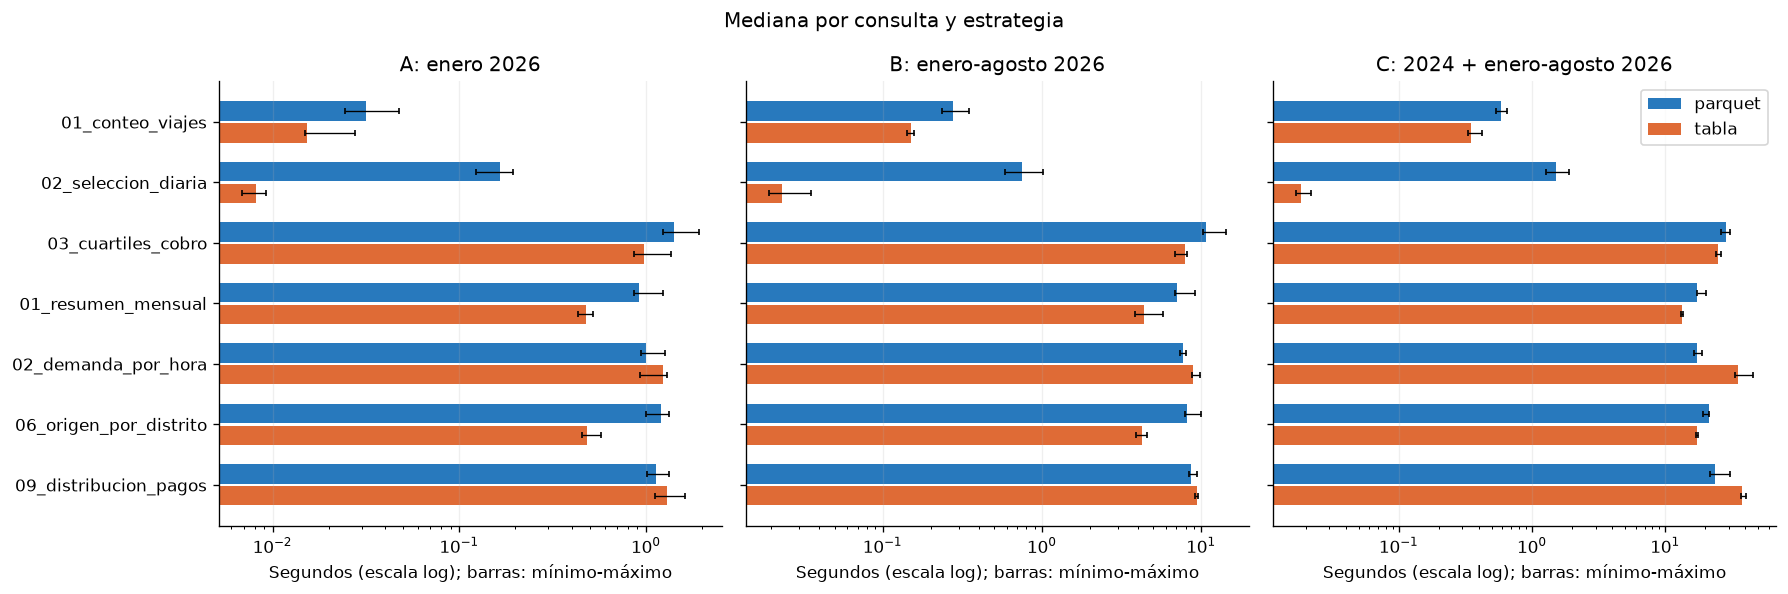

In [6]:
consultas = list(experimento["consultas"])
fig, ejes = plt.subplots(1, len(orden), figsize=(15, 5), sharey=True, squeeze=False)
y = np.arange(len(consultas))
for eje, conjunto in zip(ejes[0], orden):
    for j, estrategia in enumerate(["parquet", "tabla"]):
        d = tiempos[(tiempos.conjunto == conjunto) & (tiempos.estrategia == estrategia)].set_index("consulta").reindex(consultas)
        eje.barh(y + (j - 0.5) * 0.36, d.mediana_s, height=0.32,
                 xerr=np.vstack([d.mediana_s - d.minimo_s, d.maximo_s - d.mediana_s]),
                 color=colores[estrategia], label=estrategia, error_kw={"capsize": 2, "linewidth": 0.8})
    eje.set_xscale("log")
    eje.set_title(etiquetas[conjunto])
    eje.set_xlabel("Segundos (escala log); barras: mínimo-máximo")
    eje.grid(axis="x", alpha=0.2)
ejes[0, 0].set_yticks(y, [Path(c).stem for c in consultas])
ejes[0, 0].invert_yaxis()
ejes[0, -1].legend()
fig.suptitle("Mediana por consulta y estrategia")
fig.tight_layout()
fig.savefig(carpeta / "benchmark_consultas.png", bbox_inches="tight")
plt.show()

## Rendimiento por volumen y costo inicial

La suma de medianas representa una ronda estimada de estas siete consultas; no es un tiempo de ronda medido directamente. El número de rondas para recuperar la creación es una proyección: `creación / (suma Parquet − suma tabla)`, solo cuando el ahorro es positivo. Se supone que los tiempos permanecen estables y no hay nuevas cargas ni costos de mantenimiento.

estrategia,parquet,tabla,creacion_tabla_s,ahorro_por_ronda_s,rondas_para_recuperar
conjunto,,,,,
1 mes,5.845,4.505,4.586,1.341,3.421
8 meses,43.295,34.975,113.340,8.320,13.623
20 meses,109.832,129.012,411.102,-19.180,NaN


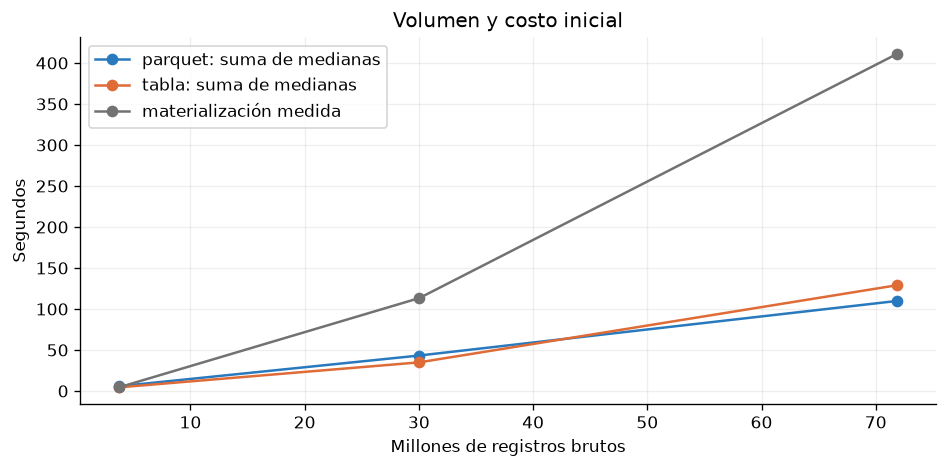

In [7]:
totales = tiempos.groupby(["conjunto", "estrategia"]).mediana_s.sum().unstack().reindex(orden)
totales["creacion_tabla_s"] = tablas.set_index("conjunto").creacion_tabla_s
totales["ahorro_por_ronda_s"] = totales.parquet - totales.tabla
totales["rondas_para_recuperar"] = (totales.creacion_tabla_s / totales.ahorro_por_ronda_s).where(totales.ahorro_por_ronda_s > 0)
display(totales.round(3))
fig, eje = plt.subplots(figsize=(8, 4))
x = tablas.set_index("conjunto").registros.reindex(orden) / 1e6
for estrategia in ["parquet", "tabla"]:
    eje.plot(x, totales[estrategia], marker="o", color=colores[estrategia], label=f"{estrategia}: suma de medianas")
eje.plot(x, totales.creacion_tabla_s, marker="o", color="#727272", label="materialización medida")
eje.set(xlabel="Millones de registros brutos", ylabel="Segundos", title="Volumen y costo inicial")
eje.legend()
eje.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(carpeta / "benchmark_volumen.png", bbox_inches="tight")
plt.show()

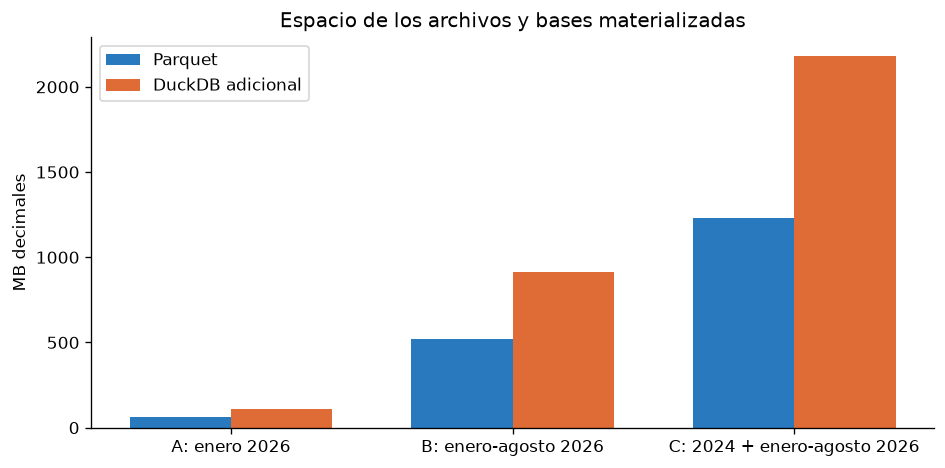

,RSS pico muestreado GiB,temporales pico muestreado GiB,disco libre final GiB
0,2.283718,0.082672,40.010033


In [8]:
fig, eje = plt.subplots(figsize=(8, 4))
x = np.arange(len(tablas))
eje.bar(x - 0.18, tablas.mb_parquet, width=0.36, color=colores["parquet"], label="Parquet")
eje.bar(x + 0.18, tablas.mb_duckdb, width=0.36, color=colores["tabla"], label="DuckDB adicional")
eje.set_xticks(x, [etiquetas[c] for c in orden])
eje.set(ylabel="MB decimales", title="Espacio de los archivos y bases materializadas")
eje.legend()
fig.tight_layout()
fig.savefig(carpeta / "benchmark_espacio.png", bbox_inches="tight")
plt.show()
display(pd.DataFrame([{"RSS pico muestreado GiB": experimento["rss_pico_muestreado_bytes"] / 1024**3,
                       "temporales pico muestreado GiB": experimento["temporales_pico_muestreado_bytes"] / 1024**3,
                       "disco libre final GiB": experimento["disco_libre_final_bytes"] / 1024**3}]))

## Interpretación de las diferencias

Contar puede usar metadatos; el filtro diario puede descartar grupos/bloques mediante estadísticas; Parquet además concilia esquemas y calcula el periodo. La tabla persiste las columnas normalizadas y el catálogo, pero implica lectura de otro formato, estadísticas distintas y más espacio. Los filtros de calidad y los percentiles requieren trabajo analítico en ambas fuentes. Las ventanas actúan sobre agregados pequeños: no se atribuye una diferencia de tiempos exclusivamente a una ventana.

Estas son explicaciones posibles. Los planes `EXPLAIN` guardados en `benchmark_planes.json` apoyan la interpretación, pero no son perfiles de ejecución y no demuestran causalidad. La gráfica muestra cómo cambia la ventaja con el volumen sin imponer un ganador universal.

In [9]:
for conjunto in orden:
    d = comparacion[comparacion.conjunto == conjunto]
    t = totales.loc[conjunto]
    ganadores = d.mas_rapida.value_counts().to_dict()
    recuperacion = f"{t.rondas_para_recuperar:.2f} rondas estimadas" if pd.notna(t.rondas_para_recuperar) else "sin recuperación para esta carga"
    display(Markdown(f"**{etiquetas[conjunto]}:** victorias por consulta {ganadores}; suma de medianas Parquet **{t.parquet:.3f} s**, tabla **{t.tabla:.3f} s**; creación **{t.creacion_tabla_s:.3f} s**; {recuperacion}."))

**A: enero 2026:** victorias por consulta {'tabla': 5, 'parquet': 2}; suma de medianas Parquet **5.845 s**, tabla **4.505 s**; creación **4.586 s**; 3.42 rondas estimadas.

**B: enero-agosto 2026:** victorias por consulta {'tabla': 5, 'parquet': 2}; suma de medianas Parquet **43.295 s**, tabla **34.975 s**; creación **113.340 s**; 13.62 rondas estimadas.

**C: 2024 + enero-agosto 2026:** victorias por consulta {'tabla': 5, 'parquet': 2}; suma de medianas Parquet **109.832 s**, tabla **129.012 s**; creación **411.102 s**; sin recuperación para esta carga.

## Ventajas, limitaciones y recomendaciones

Parquet conserva un formato portable, permite consultar nuevas entregas y evita duplicar almacenamiento. Conviene para exploración, consultas ocasionales, intercambio y cargas donde la ventaja de la tabla no recupera el costo inicial.

Materializar conserva normalización y estadísticas en una base persistente. Conviene para una carga repetida cuando el ahorro medido amortiza creación, almacenamiento adicional y mantenimiento incremental. La recomendación debe considerar las consultas concretas, su frecuencia y el volumen; no basta con que una consulta gane.

Límites: un equipo, datos locales, dos tipos de taxi, siete consultas y cinco repeticiones; caché del SO y orden temporal imperfectamente controlados; materialización previa calienta fuentes; cada consulta empieza con una conexión nueva; se mide tiempo de pared sin separar CPU/I/O; el RSS y los temporales se muestrean cada 0.5 s y pueden omitir picos breves. `memory_limit` limita principalmente el buffer manager, no toda la memoria del proceso; el estado de percentiles también consume memoria ([documentación oficial](https://duckdb.org/docs/current/guides/performance/oom)). No se generaliza a almacenamiento remoto, concurrencia ni otros equipos. Las bases no se incluyen en Git.

El ejercicio 6 queda documentado con resultados reales. La siguiente etapa puede consumir las recomendaciones; este notebook no inicia el ejercicio 7.